# Yachida CRC — Random Forest and LASSO

Runs all stages Random Forest, L1-logistic LASSO, ROC evaluation, and optional RF SHAP.

    Healthy_vs_Stage_0
    Healthy_vs_Stage_I_II
    Healthy_vs_Stage_III_IV
    Healthy_vs_Early_CRC(Stage_0 + Stage_I_II)
    Healthy_vs_Invasive_CRC(Stage_I_II + Stage_III_IV)

## 1. setup

In [10]:
# Portable setup: no Google Drive, no dependency on another notebook.
from pathlib import Path
import importlib.util
import os
import re
import shutil
import subprocess
import sys
import urllib.request
import warnings
import zipfile

try:
    from IPython.display import display
except Exception:
    display = print

try:
    from google.colab import files as colab_files
    IN_COLAB = True
except Exception:
    colab_files = None
    IN_COLAB = False

PROJECT_ROOT = Path(
    os.environ.get("YACHIDA_PROJECT_ROOT", "/content" if IN_COLAB else Path.cwd())
).expanduser().resolve()
PROJECT_ROOT.mkdir(parents=True, exist_ok=True)


def ensure_optional_package(module_name, pip_name=None):
    """Try to install a missing optional package in Colab; never mount Drive."""
    if importlib.util.find_spec(module_name) is not None:
        return True
    if not IN_COLAB:
        return False
    pip_name = pip_name or module_name
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])
    except Exception as exc:
        print(f"[WARNING] Could not install optional package {pip_name!r}: {exc}")
        return False
    return importlib.util.find_spec(module_name) is not None

FAST_MODE = os.environ.get("YACHIDA_FAST_TEST", "0") == "1"

warnings.filterwarnings("ignore")
print(f"Runtime: {'Google Colab' if IN_COLAB else 'local Jupyter/Python'}")
print(f"Project root: {PROJECT_ROOT}")

Runtime: Google Colab
Project root: /content


In [11]:
# Core imports and notebook-specific output folders.
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
TARGET_PAIRED_N = 347
PREVALENCE_THRESHOLD = 0.05
MIN_MEAN_REL_ABUNDANCE = 1e-6
TAXA_PSEUDOCOUNT = 1e-6
METABOLITE_PSEUDOCOUNT = 1.0
FDR_THRESHOLD = 0.05
LOG2FC_THRESHOLD = 0.5

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)


OUT_DIR = PROJECT_ROOT / "02_Yachida_RF_LASSO_results"
FIG_DIR = OUT_DIR / "figures"
TABLE_DIR = OUT_DIR / "tables"
ML_DIR = OUT_DIR / "ml_results"
for directory in [OUT_DIR, FIG_DIR, TABLE_DIR, ML_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
print(f"Output directory: {OUT_DIR}")

Output directory: /content/02_Yachida_RF_LASSO_results


## 2. Independent data loading and preprocessing

In [12]:
# Download, load, match, and preprocess the Yachida data independently.
REPO_URL = "https://github.com/borenstein-lab/microbiome-metabolome-curated-data.git"
REPO_NAME = "microbiome-metabolome-curated-data"
REPO_DIR = PROJECT_ROOT / REPO_NAME
DEFAULT_DATA_DIR = REPO_DIR / "data" / "processed_data" / "YACHIDA_CRC_2019"


def _download_repository_with_zip(destination):
    """Fallback for environments where git is unavailable."""
    for branch in ("master", "main"):
        url = f"https://github.com/borenstein-lab/{REPO_NAME}/archive/refs/heads/{branch}.zip"
        archive = PROJECT_ROOT / f"{REPO_NAME}-{branch}.zip"
        extracted = PROJECT_ROOT / f"{REPO_NAME}-{branch}"
        try:
            print(f"[INFO] Downloading repository ZIP from {url}")
            urllib.request.urlretrieve(url, archive)
            with zipfile.ZipFile(archive) as zf:
                zf.extractall(PROJECT_ROOT)
            if destination.exists():
                shutil.rmtree(destination)
            extracted.rename(destination)
            archive.unlink(missing_ok=True)
            return
        except Exception as exc:
            print(f"[WARNING] ZIP download for branch {branch!r} failed: {exc}")
            archive.unlink(missing_ok=True)
            if extracted.exists():
                shutil.rmtree(extracted)
    raise RuntimeError(
        "The public Yachida repository could not be downloaded. "
        "Check the runtime's internet connection, or set environment variable "
        "YACHIDA_DATA_DIR to a local YACHIDA_CRC_2019 folder."
    )


def resolve_data_dir():
    override = os.environ.get("YACHIDA_DATA_DIR")
    if override:
        data_dir = Path(override).expanduser().resolve()
        if not data_dir.exists():
            raise FileNotFoundError(f"YACHIDA_DATA_DIR does not exist: {data_dir}")
        print(f"[INFO] Using data directory from YACHIDA_DATA_DIR: {data_dir}")
        return data_dir

    if DEFAULT_DATA_DIR.exists():
        print(f"[INFO] Using existing repository data: {DEFAULT_DATA_DIR}")
        return DEFAULT_DATA_DIR

    if REPO_DIR.exists() and not DEFAULT_DATA_DIR.exists():
        print(f"[WARNING] Removing incomplete repository folder: {REPO_DIR}")
        shutil.rmtree(REPO_DIR)

    git_executable = shutil.which("git")
    if git_executable:
        try:
            print(f"[INFO] Cloning public repository into {REPO_DIR}")
            subprocess.run(
                [git_executable, "clone", "--depth", "1", REPO_URL, str(REPO_DIR)],
                cwd=PROJECT_ROOT,
                check=True,
            )
        except Exception as exc:
            print(f"[WARNING] git clone failed: {exc}")

    if not DEFAULT_DATA_DIR.exists():
        _download_repository_with_zip(REPO_DIR)

    if not DEFAULT_DATA_DIR.exists():
        raise FileNotFoundError(f"Dataset directory was not found after download: {DEFAULT_DATA_DIR}")
    return DEFAULT_DATA_DIR


DATA_DIR = resolve_data_dir()


def _clean_labels(values):
    return pd.Index([str(value).strip() for value in values])


def read_metadata(path):
    raw = pd.read_csv(path, sep="\t", low_memory=False)
    if raw.empty:
        raise ValueError(f"Metadata file is empty: {path}")

    normalized = {re.sub(r"[^a-z0-9]", "", str(col).lower()): col for col in raw.columns}
    sample_candidates = ["sample", "sampleid", "sampleidentifier", "id"]
    sample_col = next((normalized[key] for key in sample_candidates if key in normalized), None)

    if sample_col is None:
        # The curated Yachida metadata historically stores sample IDs in the second column.
        sample_col = raw.columns[1] if raw.shape[1] >= 2 else raw.columns[0]
        print(f"[WARNING] No standard sample-ID column name found; using {sample_col!r}.")

    raw[sample_col] = raw[sample_col].astype(str).str.strip()
    meta = raw.drop_duplicates(subset=[sample_col], keep="first").set_index(sample_col)
    meta.index.name = "Sample_ID"

    normalized_meta = {re.sub(r"[^a-z0-9]", "", str(col).lower()): col for col in meta.columns}
    group_candidates = ["studygroup", "group", "diseasegroup", "condition", "diagnosis"]
    group_col = next((normalized_meta[key] for key in group_candidates if key in normalized_meta), None)
    if group_col is None:
        raise KeyError(
            "No clinical group column was found. Expected a column such as "
            "'Study.Group', 'Group', 'Condition', or 'Diagnosis'."
        )
    return meta, group_col


def canonicalize_group(value):
    if pd.isna(value):
        return np.nan
    text = re.sub(r"[^a-z0-9]+", "", str(value).strip().lower())
    if text in {"healthy", "control", "controls", "normal", "hc"}:
        return "Healthy"
    if text in {"stage0", "s0", "crcstage0"}:
        return "Stage_0"
    if text in {"stageiii", "stage12", "siii", "s12", "stage1and2", "stageiandii"}:
        return "Stage_I_II"
    if text in {"stageiiiiv", "stage34", "siiiiv", "s34", "stage3and4", "stageiiiandiv"}:
        return "Stage_III_IV"
    return str(value).strip()


def read_feature_table(path, metadata_ids, duplicate_policy="sum"):
    frame = pd.read_csv(path, sep="\t", index_col=0, compression="infer", low_memory=False)
    frame.index = _clean_labels(frame.index)
    frame.columns = _clean_labels(frame.columns)
    metadata_ids = set(map(str, metadata_ids))

    index_overlap = len(set(frame.index) & metadata_ids)
    column_overlap = len(set(frame.columns) & metadata_ids)
    if column_overlap > index_overlap:
        frame = frame.T
        frame.index = _clean_labels(frame.index)
        frame.columns = _clean_labels(frame.columns)
        index_overlap = column_overlap

    if index_overlap == 0:
        raise ValueError(
            f"No sample IDs in {path.name} overlap the metadata. "
            "The table orientation or sample-ID format is not recognized."
        )

    frame = frame.loc[~frame.index.duplicated(keep="first")]
    if frame.columns.duplicated().any():
        grouped = frame.T.groupby(level=0)
        frame = grouped.mean().T if duplicate_policy == "mean" else grouped.sum().T
    return frame.apply(pd.to_numeric, errors="coerce")


def first_existing(*paths):
    for path in paths:
        if path.exists():
            return path
    raise FileNotFoundError("None of the required alternatives exists: " + ", ".join(map(str, paths)))


required_core = [DATA_DIR / "metadata.tsv", DATA_DIR / "mtb.tsv"]
missing_core = [path.name for path in required_core if not path.exists()]
if missing_core:
    raise FileNotFoundError(f"Missing required Yachida files: {missing_core} in {DATA_DIR}")

metadata_raw, ORIGINAL_GROUP_COL = read_metadata(DATA_DIR / "metadata.tsv")
metadata_raw["Group_Original"] = metadata_raw[ORIGINAL_GROUP_COL].astype(str)
metadata_raw["Group_Canonical"] = metadata_raw[ORIGINAL_GROUP_COL].map(canonicalize_group)
GROUP_COL = "Group_Canonical"
metadata_ids = set(metadata_raw.index.astype(str))

species_path = first_existing(DATA_DIR / "species.counts.tsv", DATA_DIR / "species.tsv.zip")
genera_path = first_existing(DATA_DIR / "genera.counts.tsv", DATA_DIR / "genera.tsv")
metabolomics_path = DATA_DIR / "mtb.tsv"

species_raw = read_feature_table(species_path, metadata_ids, duplicate_policy="sum")
genera_raw = read_feature_table(genera_path, metadata_ids, duplicate_policy="sum")
metabolomics_raw = read_feature_table(metabolomics_path, metadata_ids, duplicate_policy="mean")

sample_sets = {
    "metadata": set(metadata_raw.index),
    "species": set(species_raw.index),
    "genera": set(genera_raw.index),
    "metabolomics": set(metabolomics_raw.index),
}
paired_ids = sorted(set.intersection(*sample_sets.values()))
if not paired_ids:
    raise ValueError("No samples are shared across metadata, species, genera, and metabolomics.")

metadata = metadata_raw.loc[paired_ids].copy()
species_counts = species_raw.loc[paired_ids].copy()
genera_counts = genera_raw.loc[paired_ids].copy()
metabolomics = metabolomics_raw.loc[paired_ids].copy()

if len(paired_ids) != TARGET_PAIRED_N:
    print(f"[WARNING] Expected {TARGET_PAIRED_N} paired samples from the published curated set; found {len(paired_ids)}.")
else:
    print(f"[OK] Found the expected {TARGET_PAIRED_N} paired samples.")

sample_audit = pd.DataFrame({
    "Layer": list(sample_sets),
    "Samples_Loaded": [len(sample_sets[name]) for name in sample_sets],
    "Samples_In_Paired_Cohort": len(paired_ids),
})
sample_audit.to_csv(TABLE_DIR / "sample_id_audit_summary.csv", index=False)

master_mapping = metadata[["Group_Original", GROUP_COL]].copy()
master_mapping.insert(0, "Sample_ID", master_mapping.index)
master_mapping.to_csv(TABLE_DIR / "master_sample_mapping.csv", index=False)


def preprocess_taxonomy(counts):
    numeric = counts.apply(pd.to_numeric, errors="coerce").fillna(0.0).clip(lower=0.0)
    totals = numeric.sum(axis=1).replace(0.0, np.nan)
    relative = numeric.div(totals, axis=0).fillna(0.0)
    prevalence = (relative > 0).mean(axis=0)
    mean_abundance = relative.mean(axis=0)
    keep = (prevalence >= PREVALENCE_THRESHOLD) & (mean_abundance >= MIN_MEAN_REL_ABUNDANCE)
    if not keep.any():
        keep.loc[mean_abundance.nlargest(min(10, len(mean_abundance))).index] = True
    filtered = relative.loc[:, keep].copy()
    log_frame = np.log10(filtered + TAXA_PSEUDOCOUNT)
    scaled = pd.DataFrame(
        StandardScaler().fit_transform(log_frame),
        index=log_frame.index,
        columns=log_frame.columns,
    )
    return {"raw": numeric, "relative": relative, "filtered": filtered, "log": log_frame, "scaled": scaled}


def preprocess_metabolomics(frame):
    numeric = frame.apply(pd.to_numeric, errors="coerce")
    keep = numeric.notna().mean(axis=0).ge(0.20) & numeric.var(axis=0, skipna=True).fillna(0).gt(0)
    if not keep.any():
        keep.loc[numeric.notna().mean(axis=0).nlargest(min(10, numeric.shape[1])).index] = True
    filtered = numeric.loc[:, keep].copy()
    log_frame = np.log10(filtered.clip(lower=0.0) + METABOLITE_PSEUDOCOUNT)
    medians = log_frame.median(axis=0, skipna=True)
    imputed = log_frame.fillna(medians).fillna(0.0)
    scaled = pd.DataFrame(
        StandardScaler().fit_transform(imputed),
        index=imputed.index,
        columns=imputed.columns,
    )
    return {"raw": numeric, "filtered": filtered, "log": log_frame, "imputed": imputed, "scaled": scaled}


species_prep = preprocess_taxonomy(species_counts)
genera_prep = preprocess_taxonomy(genera_counts)
metabolomics_prep = preprocess_metabolomics(metabolomics)

data_blocks = {
    "species": species_prep["scaled"],
    "genera": genera_prep["scaled"],
    "metabolomics": metabolomics_prep["scaled"],
}
differential_blocks = {
    "species": species_prep["filtered"],
    "genera": genera_prep["filtered"],
    "metabolomics": metabolomics_prep["filtered"],
}
ml_blocks = {
    "species": species_prep["log"].add_prefix("species|"),
    "genera": genera_prep["log"].add_prefix("genera|"),
    "metabolomics": metabolomics_prep["imputed"].add_prefix("metabolite|"),
}
ml_blocks["species_plus_metabolomics"] = pd.concat([ml_blocks["species"], ml_blocks["metabolomics"]], axis=1)
ml_blocks["genera_plus_metabolomics"] = pd.concat([ml_blocks["genera"], ml_blocks["metabolomics"]], axis=1)

for name, frame in data_blocks.items():
    frame.to_csv(TABLE_DIR / f"{name}_preprocessed_scaled.csv")

print("Clinical groups in the paired cohort:")
display(metadata[GROUP_COL].value_counts().rename_axis("Group").to_frame("N"))
print("Preprocessed feature counts:", {name: frame.shape[1] for name, frame in data_blocks.items()})

[INFO] Using existing repository data: /content/microbiome-metabolome-curated-data/data/processed_data/YACHIDA_CRC_2019
[OK] Found the expected 347 paired samples.
Clinical groups in the paired cohort:


,N
Group,
Healthy,127
Stage_I_II,69
Stage_III_IV,54
MP,40
HS,30
Stage_0,27


Preprocessed feature counts: {'species': 6940, 'genera': 1870, 'metabolomics': 446}


## 3. Contrasts and differential helpers

In [13]:
# Define robust contrasts and differential-testing helpers.
CONTRAST_CANDIDATES = {
    "Healthy_vs_Stage_0": (["Healthy"], ["Stage_0"]),
    "Healthy_vs_Stage_I_II": (["Healthy"], ["Stage_I_II"]),
    "Healthy_vs_Stage_III_IV": (["Healthy"], ["Stage_III_IV"]),
    "Healthy_vs_Early_CRC": (["Healthy"], ["Stage_0", "Stage_I_II"]),
    "Healthy_vs_Invasive_CRC": (["Healthy"], ["Stage_I_II", "Stage_III_IV"]),
}
available_groups = set(metadata[GROUP_COL].dropna().astype(str).unique())
ACTIVE_CONTRASTS = {
    name: {"Group_A_Labels": group_a, "Group_B_Labels": group_b}
    for name, (group_a, group_b) in CONTRAST_CANDIDATES.items()
    if set(group_a + group_b).issubset(available_groups)
}
if not ACTIVE_CONTRASTS:
    raise ValueError(f"No expected Healthy-versus-CRC contrasts are available. Labels: {sorted(available_groups)}")

contrast_rows = []
for name, spec in ACTIVE_CONTRASTS.items():
    contrast_rows.append({
        "Contrast": name,
        "Group_A": "+".join(spec["Group_A_Labels"]),
        "Group_B": "+".join(spec["Group_B_Labels"]),
        "N_Group_A": int(metadata[GROUP_COL].isin(spec["Group_A_Labels"]).sum()),
        "N_Group_B": int(metadata[GROUP_COL].isin(spec["Group_B_Labels"]).sum()),
    })
contrast_table = pd.DataFrame(contrast_rows)
contrast_table.to_csv(TABLE_DIR / "active_contrasts.csv", index=False)
display(contrast_table)


def get_contrast_data(frame, contrast_name):
    spec = ACTIVE_CONTRASTS[contrast_name]
    labels_a = spec["Group_A_Labels"]
    labels_b = spec["Group_B_Labels"]
    ids = metadata.index[metadata[GROUP_COL].isin(labels_a + labels_b)]
    X = frame.loc[ids].copy()
    y = metadata.loc[ids, GROUP_COL].isin(labels_b).astype(int)
    return X, y


def run_differential(frame, group_a_ids, group_b_ids, is_microbiome):
    pseudo = TAXA_PSEUDOCOUNT if is_microbiome else METABOLITE_PSEUDOCOUNT
    records = []
    for feature in frame.columns:
        values_a = pd.to_numeric(frame.loc[group_a_ids, feature], errors="coerce").dropna()
        values_b = pd.to_numeric(frame.loc[group_b_ids, feature], errors="coerce").dropna()
        if values_a.empty or values_b.empty:
            statistic, p_value = np.nan, 1.0
        else:
            try:
                statistic, p_value = mannwhitneyu(values_a, values_b, alternative="two-sided")
            except Exception:
                statistic, p_value = np.nan, 1.0
        mean_a = float(values_a.mean()) if not values_a.empty else np.nan
        mean_b = float(values_b.mean()) if not values_b.empty else np.nan
        fold_change = np.log2((mean_b + pseudo) / (mean_a + pseudo)) if np.isfinite(mean_a) and np.isfinite(mean_b) else np.nan
        records.append({
            "Feature": feature,
            "Mean_Group_A": mean_a,
            "Mean_Group_B": mean_b,
            "Log2FC_GroupB_vs_GroupA": fold_change,
            "MannWhitneyU": statistic,
            "P_Value": p_value,
        })
    result = pd.DataFrame(records)
    if result.empty:
        return pd.DataFrame(columns=[
            "Feature", "Mean_Group_A", "Mean_Group_B", "Log2FC_GroupB_vs_GroupA",
            "MannWhitneyU", "P_Value", "FDR_BH", "Significant_FDR"
        ])
    result["FDR_BH"] = multipletests(result["P_Value"].fillna(1.0), method="fdr_bh")[1]
    result["Significant_FDR"] = result["FDR_BH"] < FDR_THRESHOLD
    return result.sort_values(["FDR_BH", "P_Value"], kind="stable").reset_index(drop=True)


def draw_volcano(result, title, ax):
    if result.empty:
        ax.text(0.5, 0.5, "No features available", ha="center", va="center")
        ax.set_title(title)
        return
    plot_data = result.copy()
    plot_data["NegLog10FDR"] = -np.log10(plot_data["FDR_BH"].clip(lower=1e-300))
    plot_data["Status"] = "Not significant"
    plot_data.loc[
        (plot_data["FDR_BH"] < FDR_THRESHOLD) &
        (plot_data["Log2FC_GroupB_vs_GroupA"] >= LOG2FC_THRESHOLD),
        "Status",
    ] = "Higher in disease"
    plot_data.loc[
        (plot_data["FDR_BH"] < FDR_THRESHOLD) &
        (plot_data["Log2FC_GroupB_vs_GroupA"] <= -LOG2FC_THRESHOLD),
        "Status",
    ] = "Lower in disease"
    for status_name, status_frame in plot_data.groupby("Status", sort=True):
        ax.scatter(
            status_frame["Log2FC_GroupB_vs_GroupA"],
            status_frame["NegLog10FDR"],
            s=20,
            alpha=0.7,
            label=str(status_name),
        )
    ax.axhline(-np.log10(FDR_THRESHOLD), linestyle="--", linewidth=1)
    ax.axvline(LOG2FC_THRESHOLD, linestyle="--", linewidth=1)
    ax.axvline(-LOG2FC_THRESHOLD, linestyle="--", linewidth=1)
    ax.set(title=title, xlabel="log2 fold change", ylabel="-log10(FDR)")
    ax.legend(fontsize=7, title=None)

,Contrast,Group_A,Group_B,N_Group_A,N_Group_B
0,Healthy_vs_Stage_0,Healthy,Stage_0,127,27
1,Healthy_vs_Stage_I_II,Healthy,Stage_I_II,127,69
2,Healthy_vs_Stage_III_IV,Healthy,Stage_III_IV,127,54
3,Healthy_vs_Early_CRC,Healthy,Stage_0+Stage_I_II,127,96
4,Healthy_vs_Invasive_CRC,Healthy,Stage_I_II+Stage_III_IV,127,123


## 4. ML helpers

In [14]:
# Robust ML helpers. All feature selection occurs wiyhin pipeline.
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, train_test_split, cross_val_score
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

TEST_SIZE = 0.25
OUTER_CV_SPLITS = 2 if FAST_MODE else 5


class SafeSelectKBest(BaseEstimator, TransformerMixin):
    """Select at most k features, even if an upstream step leaves fewer columns."""
    def __init__(self, k=20):
        self.k = k

    def fit(self, X, y):
        n_features = int(np.asarray(X).shape[1])
        if n_features < 1:
            raise ValueError("No features are available for supervised selection.")
        self.k_effective_ = max(1, min(int(self.k), n_features))
        self.selector_ = SelectKBest(score_func=f_classif, k=self.k_effective_)
        self.selector_.fit(X, y)
        self.scores_ = self.selector_.scores_
        self.pvalues_ = self.selector_.pvalues_
        return self

    def transform(self, X):
        return self.selector_.transform(X)

    def get_support(self, indices=False):
        return self.selector_.get_support(indices=indices)


def choose_k(block_name, n_features, n_samples):
    cap = 75 if "plus" in block_name else (30 if block_name == "metabolomics" else 50)
    fraction = 0.50 if "plus" in block_name else 0.25
    adaptive = max(5, int(math.floor(fraction * n_samples)))
    return max(1, min(int(n_features), cap, adaptive))


def make_rf_pipeline(k):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("feature_select", SafeSelectKBest(k=k)),
        ("rf", RandomForestClassifier(
            n_estimators=40 if FAST_MODE else 180,
            random_state=RANDOM_STATE,
            class_weight="balanced",
            max_features="sqrt",
            min_samples_leaf=2,
            n_jobs=-1,
        )),
    ])


def make_lasso_pipeline(k):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("feature_select", SafeSelectKBest(k=k)),
        ("scaler", StandardScaler()),
        ("lasso", LogisticRegression(
            penalty="l1",
            C=0.1,
            solver="liblinear",
            class_weight="balanced",
            max_iter=5000,
            random_state=RANDOM_STATE,
        )),
    ])


def selected_feature_names(fitted_pipeline, original_columns):
    selector = fitted_pipeline.named_steps["feature_select"]
    return np.asarray(original_columns, dtype=object)[selector.get_support()]


def safe_cv_scores(model, X, y, cv):
    try:
        scores = cross_val_score(model, X, y, cv=cv, scoring="roc_auc", n_jobs=1, error_score=np.nan)
        return np.asarray(scores, dtype=float)
    except Exception as exc:
        print(f"[WARNING] Cross-validation failed: {exc}")
        return np.asarray([np.nan])

## 5. Random Forest and LASSO

[OK] Healthy_vs_Stage_0 | species | RandomForest: AUC=0.518
[OK] Healthy_vs_Stage_0 | species | LASSO: AUC=0.451


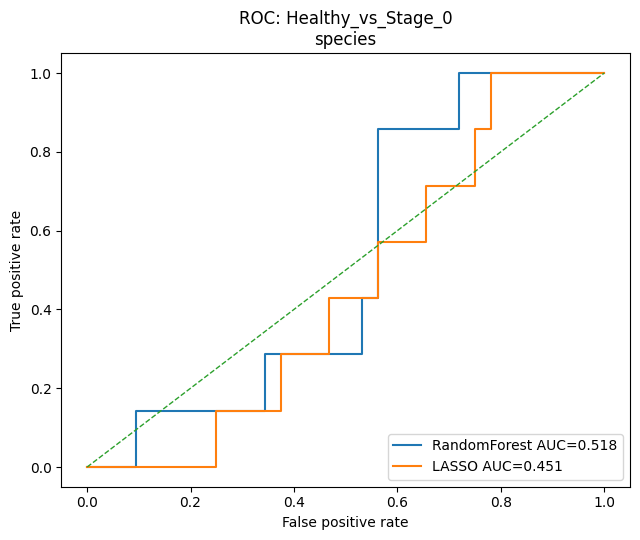

[OK] Healthy_vs_Stage_0 | genera | RandomForest: AUC=0.549
[OK] Healthy_vs_Stage_0 | genera | LASSO: AUC=0.518


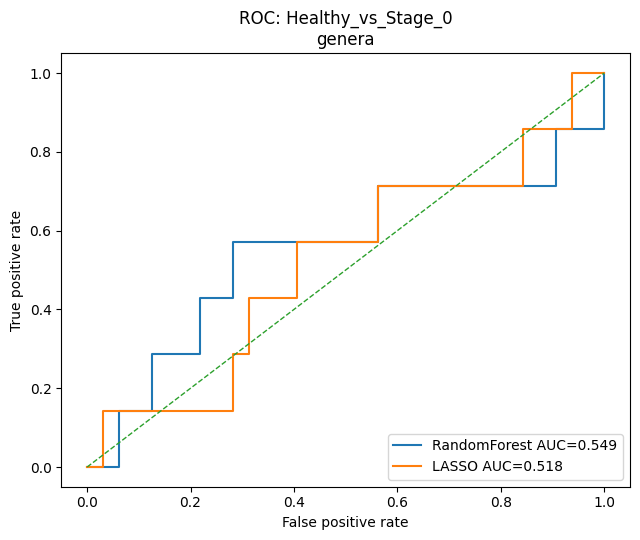

[OK] Healthy_vs_Stage_0 | metabolomics | RandomForest: AUC=0.616
[OK] Healthy_vs_Stage_0 | metabolomics | LASSO: AUC=0.589


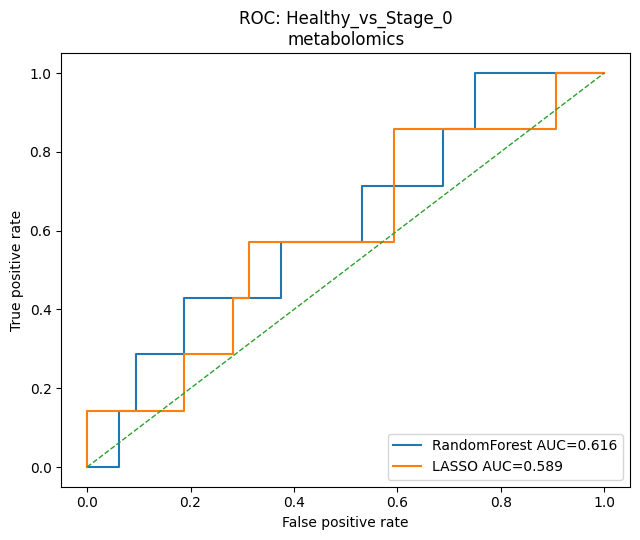

[OK] Healthy_vs_Stage_0 | species_plus_metabolomics | RandomForest: AUC=0.585
[OK] Healthy_vs_Stage_0 | species_plus_metabolomics | LASSO: AUC=0.496


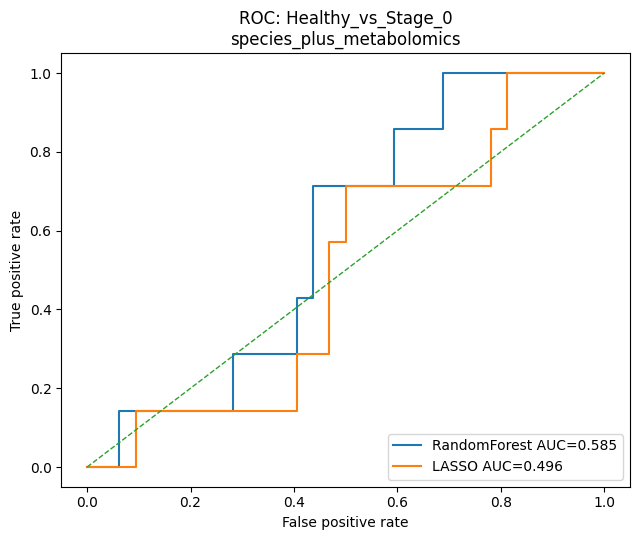

[OK] Healthy_vs_Stage_0 | genera_plus_metabolomics | RandomForest: AUC=0.674
[OK] Healthy_vs_Stage_0 | genera_plus_metabolomics | LASSO: AUC=0.531


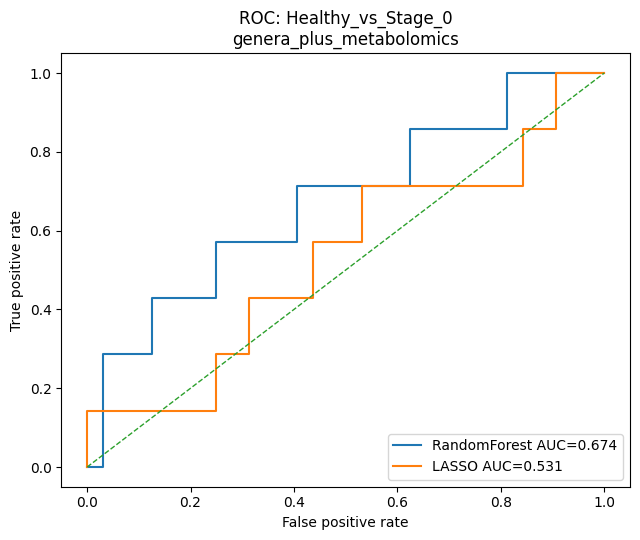

[OK] Healthy_vs_Stage_I_II | species | RandomForest: AUC=0.623
[OK] Healthy_vs_Stage_I_II | species | LASSO: AUC=0.507


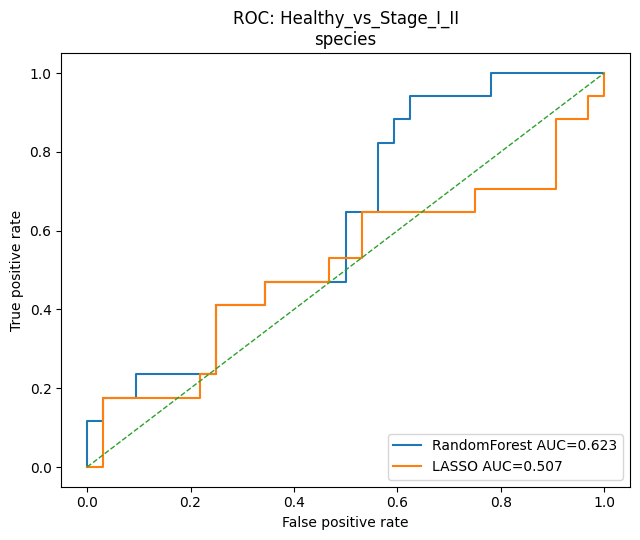

[OK] Healthy_vs_Stage_I_II | genera | RandomForest: AUC=0.664
[OK] Healthy_vs_Stage_I_II | genera | LASSO: AUC=0.654


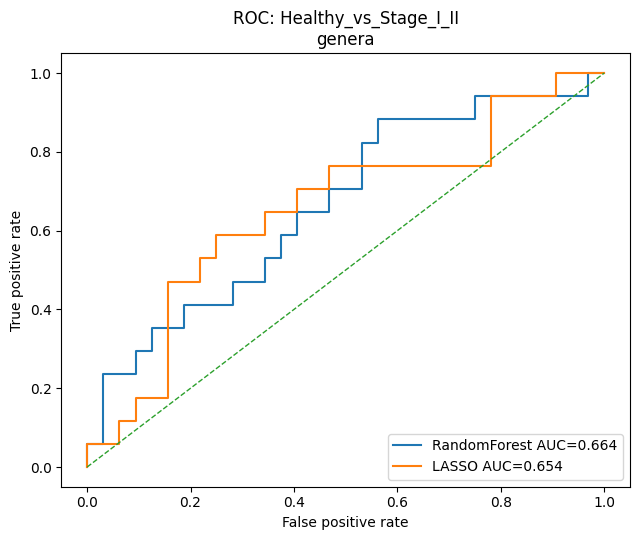

[OK] Healthy_vs_Stage_I_II | metabolomics | RandomForest: AUC=0.619
[OK] Healthy_vs_Stage_I_II | metabolomics | LASSO: AUC=0.629


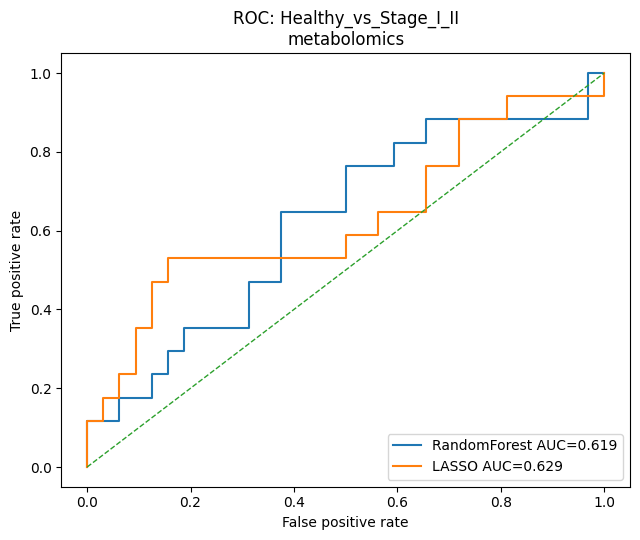

[OK] Healthy_vs_Stage_I_II | species_plus_metabolomics | RandomForest: AUC=0.632
[OK] Healthy_vs_Stage_I_II | species_plus_metabolomics | LASSO: AUC=0.607


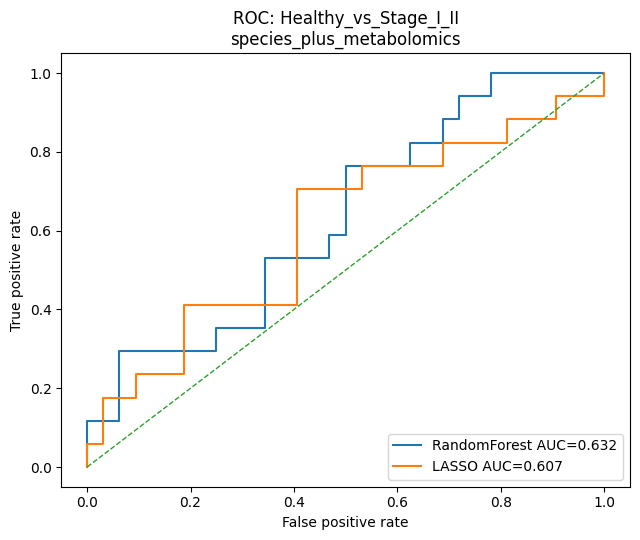

[OK] Healthy_vs_Stage_I_II | genera_plus_metabolomics | RandomForest: AUC=0.616
[OK] Healthy_vs_Stage_I_II | genera_plus_metabolomics | LASSO: AUC=0.688


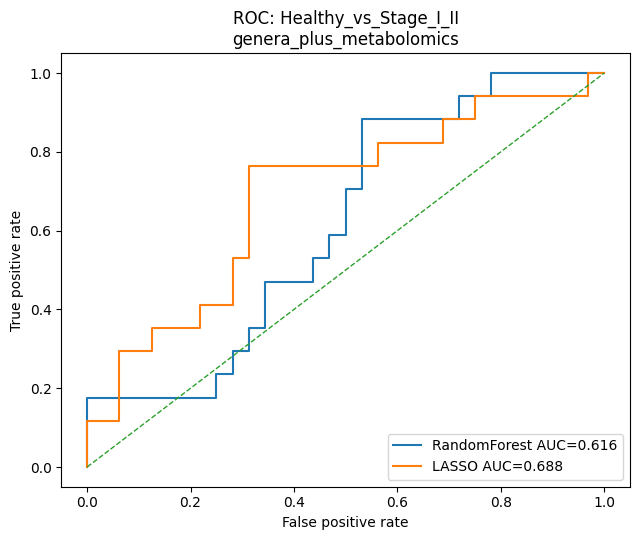

[OK] Healthy_vs_Stage_III_IV | species | RandomForest: AUC=0.779
[OK] Healthy_vs_Stage_III_IV | species | LASSO: AUC=0.752


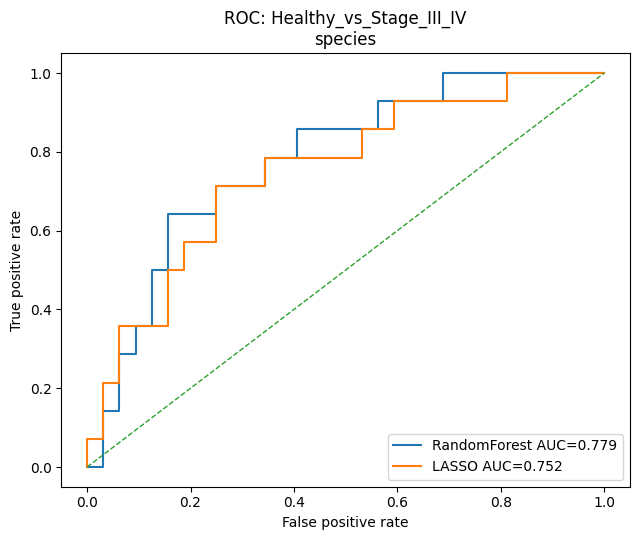

[OK] Healthy_vs_Stage_III_IV | genera | RandomForest: AUC=0.761
[OK] Healthy_vs_Stage_III_IV | genera | LASSO: AUC=0.761


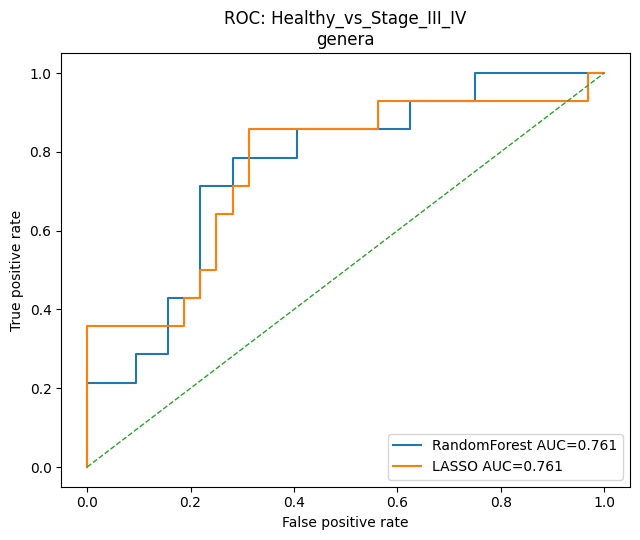

[OK] Healthy_vs_Stage_III_IV | metabolomics | RandomForest: AUC=0.694
[OK] Healthy_vs_Stage_III_IV | metabolomics | LASSO: AUC=0.685


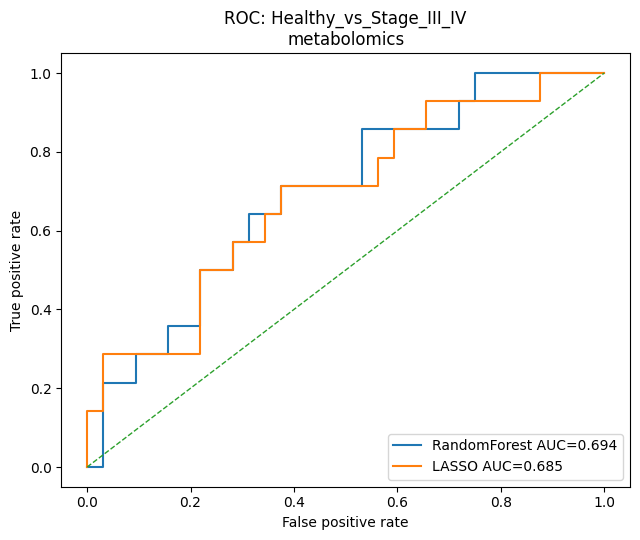

[OK] Healthy_vs_Stage_III_IV | species_plus_metabolomics | RandomForest: AUC=0.783
[OK] Healthy_vs_Stage_III_IV | species_plus_metabolomics | LASSO: AUC=0.728


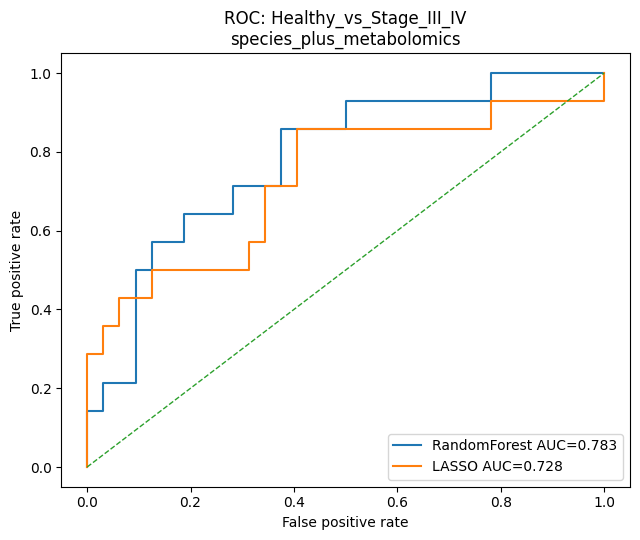

[OK] Healthy_vs_Stage_III_IV | genera_plus_metabolomics | RandomForest: AUC=0.779
[OK] Healthy_vs_Stage_III_IV | genera_plus_metabolomics | LASSO: AUC=0.783


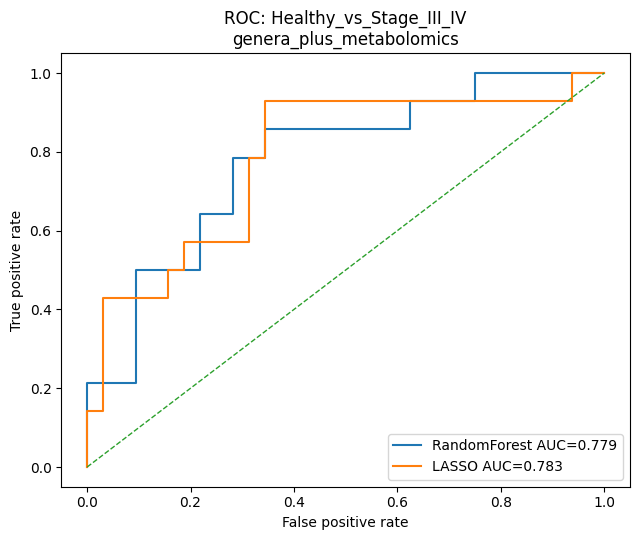

[OK] Healthy_vs_Early_CRC | species | RandomForest: AUC=0.525
[OK] Healthy_vs_Early_CRC | species | LASSO: AUC=0.556


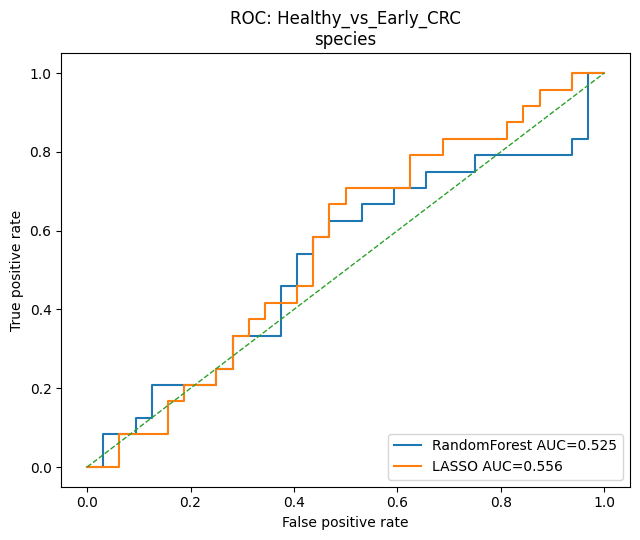

[OK] Healthy_vs_Early_CRC | genera | RandomForest: AUC=0.612
[OK] Healthy_vs_Early_CRC | genera | LASSO: AUC=0.536


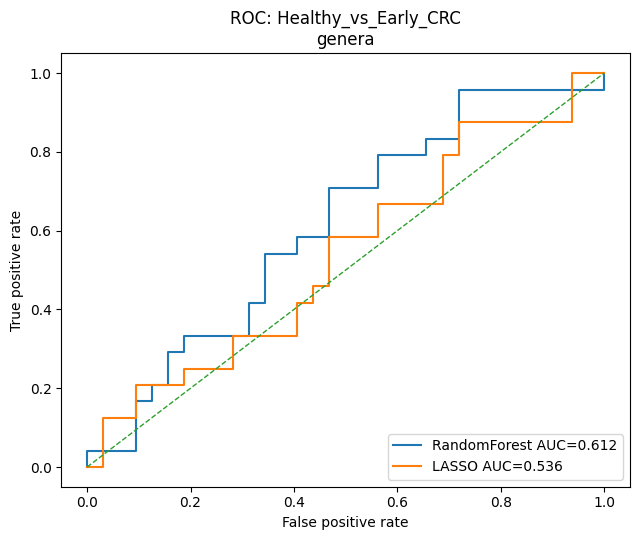

[OK] Healthy_vs_Early_CRC | metabolomics | RandomForest: AUC=0.632
[OK] Healthy_vs_Early_CRC | metabolomics | LASSO: AUC=0.615


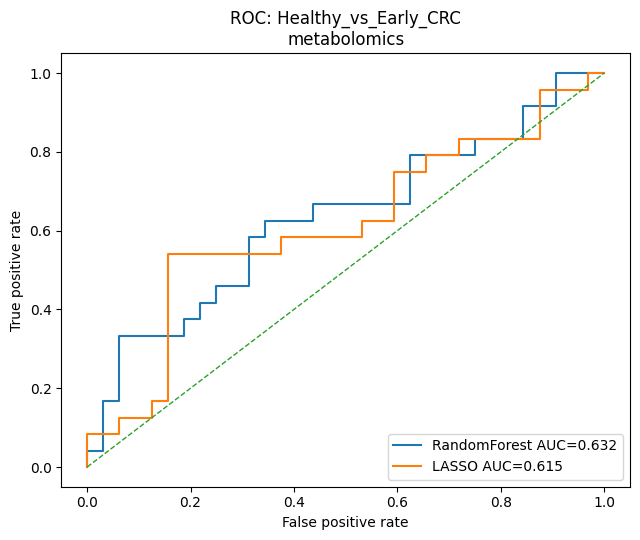

[OK] Healthy_vs_Early_CRC | species_plus_metabolomics | RandomForest: AUC=0.604
[OK] Healthy_vs_Early_CRC | species_plus_metabolomics | LASSO: AUC=0.626


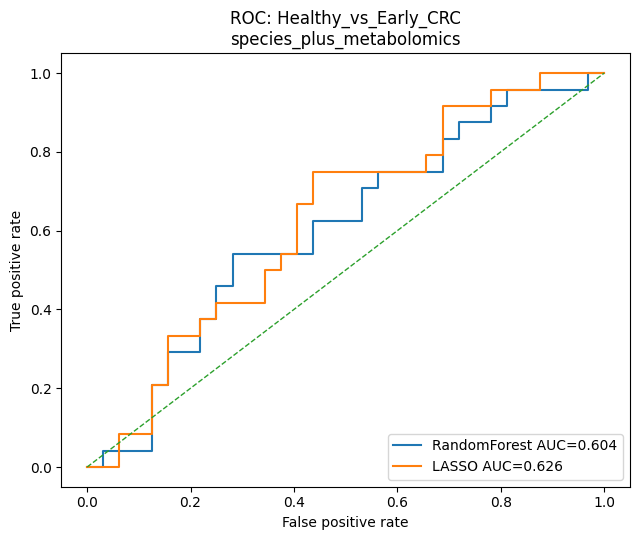

[OK] Healthy_vs_Early_CRC | genera_plus_metabolomics | RandomForest: AUC=0.626
[OK] Healthy_vs_Early_CRC | genera_plus_metabolomics | LASSO: AUC=0.574


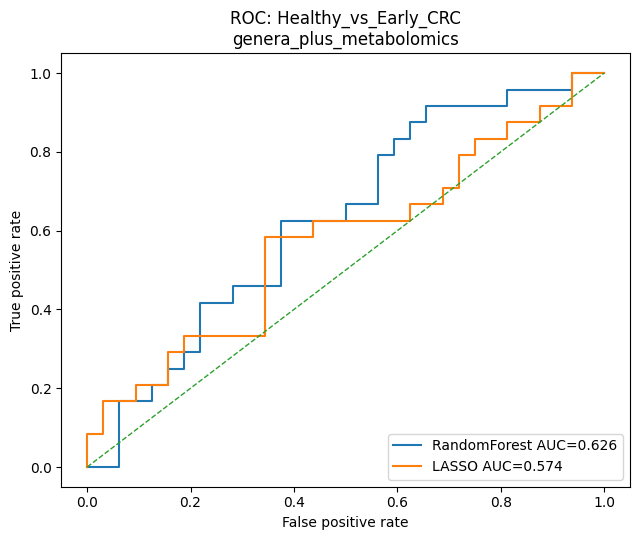

[OK] Healthy_vs_Invasive_CRC | species | RandomForest: AUC=0.731
[OK] Healthy_vs_Invasive_CRC | species | LASSO: AUC=0.680


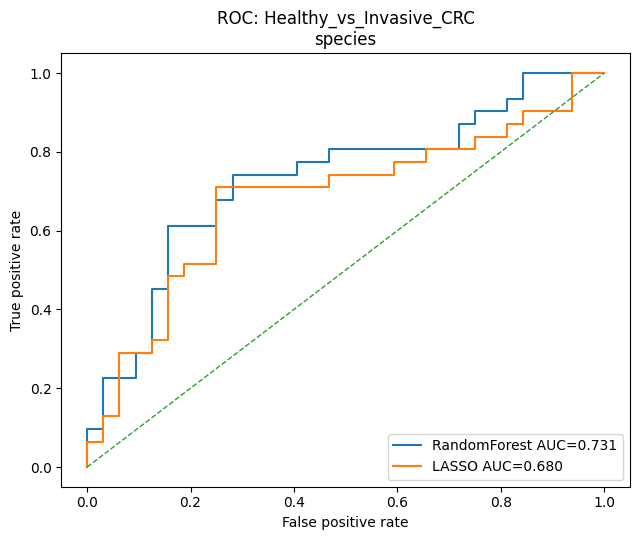

[OK] Healthy_vs_Invasive_CRC | genera | RandomForest: AUC=0.661
[OK] Healthy_vs_Invasive_CRC | genera | LASSO: AUC=0.611


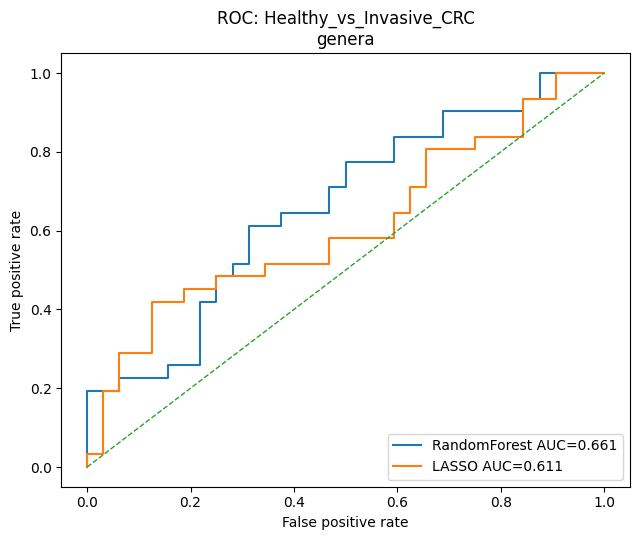

[OK] Healthy_vs_Invasive_CRC | metabolomics | RandomForest: AUC=0.668
[OK] Healthy_vs_Invasive_CRC | metabolomics | LASSO: AUC=0.601


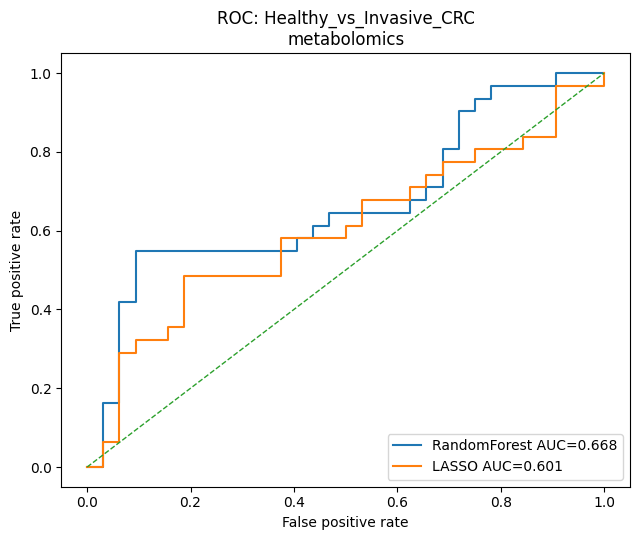

[OK] Healthy_vs_Invasive_CRC | species_plus_metabolomics | RandomForest: AUC=0.708
[OK] Healthy_vs_Invasive_CRC | species_plus_metabolomics | LASSO: AUC=0.618


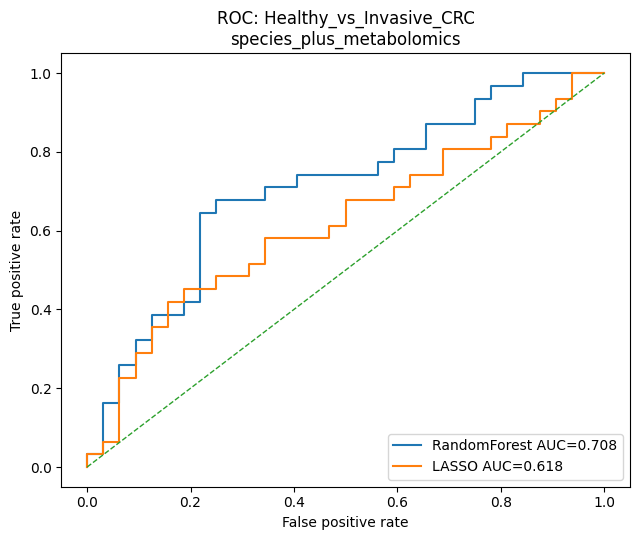

[OK] Healthy_vs_Invasive_CRC | genera_plus_metabolomics | RandomForest: AUC=0.639
[OK] Healthy_vs_Invasive_CRC | genera_plus_metabolomics | LASSO: AUC=0.640


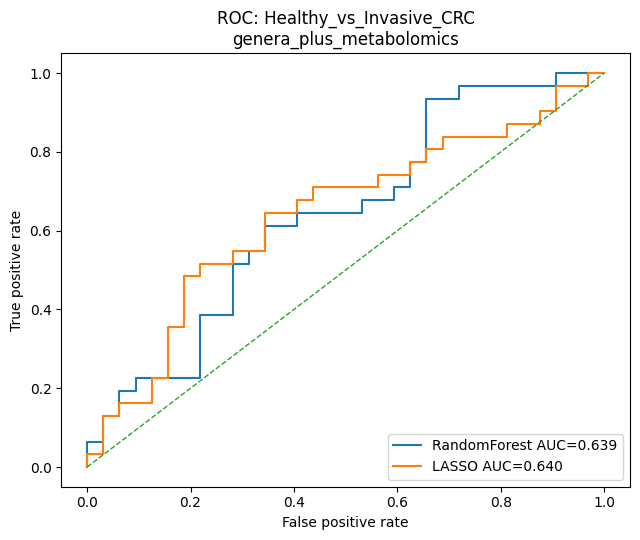

,Contrast,Feature_Block,Model,Status,N_Total,N_Train,N_Test,N_Features_Input,N_Features_Selected,CV_Splits,CV_ROC_AUC_Mean,CV_ROC_AUC_SD,Holdout_ROC_AUC,Holdout_Average_Precision,Error
26,Healthy_vs_Stage_III_IV,species_plus_metabolomics,RandomForest,ok,181,135,46,7386,67,5,0.819119,0.062455,0.783482,0.635113,
29,Healthy_vs_Stage_III_IV,genera_plus_metabolomics,LASSO,ok,181,135,46,2316,67,5,0.762196,0.050534,0.783482,0.662451,
20,Healthy_vs_Stage_III_IV,species,RandomForest,ok,181,135,46,6940,33,5,0.810168,0.057524,0.779018,0.564053,
28,Healthy_vs_Stage_III_IV,genera_plus_metabolomics,RandomForest,ok,181,135,46,2316,67,5,0.780867,0.061341,0.779018,0.644239,
22,Healthy_vs_Stage_III_IV,genera,RandomForest,ok,181,135,46,1870,33,5,0.783804,0.054570,0.761161,0.613808,
23,Healthy_vs_Stage_III_IV,genera,LASSO,ok,181,135,46,1870,33,5,0.767315,0.046342,0.761161,0.668247,
21,Healthy_vs_Stage_III_IV,species,LASSO,ok,181,135,46,6940,33,5,0.743986,0.080723,0.752232,0.589489,
40,Healthy_vs_Invasive_CRC,species,RandomForest,ok,250,187,63,6940,46,5,0.735814,0.070815,0.730847,0.734819,
27,Healthy_vs_Stage_III_IV,species_plus_metabolomics,LASSO,ok,181,135,46,7386,67,5,0.760420,0.131441,0.727679,0.655366,
46,Healthy_vs_Invasive_CRC,species_plus_metabolomics,RandomForest,ok,250,187,63,7386,75,5,0.741259,0.058080,0.707661,0.692229,


In [15]:
# Random Forest and LASSO evaluation.
ml_summary = []
rf_feature_tables = []
lasso_feature_tables = []

ml_contrast_names = list(ACTIVE_CONTRASTS)[:2] if FAST_MODE else list(ACTIVE_CONTRASTS)
ml_block_items = list(ml_blocks.items())[:2] if FAST_MODE else list(ml_blocks.items())
for contrast_name in ml_contrast_names:
    for block_name, X in ml_block_items:
        X_sub, y = get_contrast_data(X, contrast_name)
        class_counts = y.value_counts()
        min_class = int(class_counts.min()) if len(class_counts) == 2 else 0
        if len(class_counts) != 2 or min_class < 4:
            print(f"[WARNING] Skipping {contrast_name} / {block_name}: class counts {class_counts.to_dict()}")
            continue

        cv_splits = min(OUTER_CV_SPLITS, min_class)
        cv = StratifiedKFold(n_splits=cv_splits, shuffle=True, random_state=RANDOM_STATE)
        X_train, X_test, y_train, y_test = train_test_split(
            X_sub, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
        )
        k = choose_k(block_name, X_sub.shape[1], X_train.shape[0])
        models = {"RandomForest": make_rf_pipeline(k), "LASSO": make_lasso_pipeline(k)}
        roc_rows = []

        for model_name, model in models.items():
            try:
                cv_scores = safe_cv_scores(model, X_sub, y, cv)
                model.fit(X_train, y_train)
                y_score = model.predict_proba(X_test)[:, 1]
                holdout_auc = float(roc_auc_score(y_test, y_score))
                holdout_ap = float(average_precision_score(y_test, y_score))
                selected_names = selected_feature_names(model, X_sub.columns)

                record = {
                    "Contrast": contrast_name,
                    "Feature_Block": block_name,
                    "Model": model_name,
                    "Status": "ok",
                    "N_Total": len(y),
                    "N_Train": len(y_train),
                    "N_Test": len(y_test),
                    "N_Features_Input": X_sub.shape[1],
                    "N_Features_Selected": len(selected_names),
                    "CV_Splits": cv_splits,
                    "CV_ROC_AUC_Mean": float(np.nanmean(cv_scores)) if np.isfinite(cv_scores).any() else np.nan,
                    "CV_ROC_AUC_SD": float(np.nanstd(cv_scores)) if np.isfinite(cv_scores).any() else np.nan,
                    "Holdout_ROC_AUC": holdout_auc,
                    "Holdout_Average_Precision": holdout_ap,
                    "Error": "",
                }
                ml_summary.append(record)

                if model_name == "RandomForest":
                    importance = model.named_steps["rf"].feature_importances_
                    table = pd.DataFrame({
                        "Contrast": contrast_name,
                        "Feature_Block": block_name,
                        "Feature": selected_names,
                        "RF_Importance": importance,
                    }).sort_values("RF_Importance", ascending=False)
                    rf_feature_tables.append(table)
                    table.to_csv(ML_DIR / f"rf_feature_importance_{block_name}_{contrast_name}.csv", index=False)
                else:
                    coef = model.named_steps["lasso"].coef_.ravel()
                    table = pd.DataFrame({
                        "Contrast": contrast_name,
                        "Feature_Block": block_name,
                        "Feature": selected_names,
                        "LASSO_Coefficient": coef,
                        "Abs_Coefficient": np.abs(coef),
                        "Selected_By_LASSO": coef != 0,
                    }).sort_values("Abs_Coefficient", ascending=False)
                    lasso_feature_tables.append(table)
                    table.to_csv(ML_DIR / f"lasso_coefficients_{block_name}_{contrast_name}.csv", index=False)

                fpr, tpr, _ = roc_curve(y_test, y_score)
                roc_rows.append((model_name, fpr, tpr, holdout_auc))
                print(f"[OK] {contrast_name} | {block_name} | {model_name}: AUC={holdout_auc:.3f}")
            except Exception as exc:
                print(f"[WARNING] Model failed for {contrast_name} / {block_name} / {model_name}: {exc}")
                ml_summary.append({
                    "Contrast": contrast_name,
                    "Feature_Block": block_name,
                    "Model": model_name,
                    "Status": "failed",
                    "N_Total": len(y),
                    "N_Train": len(y_train),
                    "N_Test": len(y_test),
                    "N_Features_Input": X_sub.shape[1],
                    "N_Features_Selected": np.nan,
                    "CV_Splits": cv_splits,
                    "CV_ROC_AUC_Mean": np.nan,
                    "CV_ROC_AUC_SD": np.nan,
                    "Holdout_ROC_AUC": np.nan,
                    "Holdout_Average_Precision": np.nan,
                    "Error": str(exc),
                })

        if roc_rows:
            plt.figure(figsize=(6.5, 5.5))
            for model_name, fpr, tpr, auc_value in roc_rows:
                plt.plot(fpr, tpr, label=f"{model_name} AUC={auc_value:.3f}")
            plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
            plt.title(f"ROC: {contrast_name}\n{block_name}")
            plt.xlabel("False positive rate")
            plt.ylabel("True positive rate")
            plt.legend(loc="lower right")
            plt.tight_layout()
            plt.savefig(ML_DIR / f"roc_curve_{block_name}_{contrast_name}.png", dpi=250, bbox_inches="tight")
            plt.show()
            plt.close()

ml_summary_df = pd.DataFrame(ml_summary)
ml_summary_df.to_csv(ML_DIR / "ml_roc_auc_summary.csv", index=False)
if rf_feature_tables:
    pd.concat(rf_feature_tables, ignore_index=True).to_csv(ML_DIR / "rf_feature_importance_all_models.csv", index=False)
if lasso_feature_tables:
    pd.concat(lasso_feature_tables, ignore_index=True).to_csv(ML_DIR / "lasso_coefficients_all_models.csv", index=False)

display(ml_summary_df.sort_values("Holdout_ROC_AUC", ascending=False, na_position="last").head(20))

## 6. SHAP

In [16]:
HAS_SHAP = ensure_optional_package("shap", "shap")
shap_status = {"Status": "skipped", "Reason": "No suitable contrast/model"}

if HAS_SHAP:
    try:
        import shap
        preferred = "Healthy_vs_Stage_III_IV" if "Healthy_vs_Stage_III_IV" in ACTIVE_CONTRASTS else next(iter(ACTIVE_CONTRASTS))
        block_name = "genera_plus_metabolomics"
        X_sub, y = get_contrast_data(ml_blocks[block_name], preferred)
        if y.value_counts().min() >= 4:
            X_train, X_test, y_train, y_test = train_test_split(
                X_sub, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
            )
            k = choose_k(block_name, X_sub.shape[1], X_train.shape[0])
            pipe = make_rf_pipeline(k)
            pipe.fit(X_train, y_train)
            imputed = pipe.named_steps["imputer"].transform(X_test)
            selected = pipe.named_steps["feature_select"].transform(imputed)
            feature_names = selected_feature_names(pipe, X_train.columns)
            X_shap = pd.DataFrame(selected, columns=feature_names, index=X_test.index)

            explainer = shap.TreeExplainer(pipe.named_steps["rf"])
            values = explainer.shap_values(X_shap)
            if hasattr(values, "values"):
                values = values.values
            if isinstance(values, list):
                values = values[-1]
            values = np.asarray(values)
            if values.ndim == 3:
                values = values[:, :, -1]
            mean_abs = np.abs(values).mean(axis=0)
            shap_table = pd.DataFrame({"Feature": feature_names, "Mean_Absolute_SHAP": mean_abs})
            shap_table = shap_table.sort_values("Mean_Absolute_SHAP", ascending=False).head(20)
            shap_table.to_csv(ML_DIR / f"rf_shap_top20_{block_name}_{preferred}.csv", index=False)
            display(shap_table)
            shap_status = {"Status": "ok", "Reason": ""}
    except Exception as exc:
        shap_status = {"Status": "skipped_after_error", "Reason": str(exc)}
        print(f"[WARNING] Optional SHAP section was skipped: {exc}")
else:
    shap_status = {"Status": "skipped", "Reason": "shap package unavailable"}

pd.DataFrame([shap_status]).to_csv(ML_DIR / "rf_shap_status.csv", index=False)

,Feature,Mean_Absolute_SHAP
28,genera|d__Bacteria;p__Firmicutes_A;c__Clostrid...,0.047777
25,genera|d__Bacteria;p__Firmicutes_A;c__Clostrid...,0.034762
29,genera|d__Bacteria;p__Fusobacteriota;c__Fusoba...,0.029432
32,genera|d__Bacteria;p__Firmicutes;c__Bacilli;o_...,0.022386
18,genera|d__Bacteria;p__Actinobacteriota;c__Cori...,0.016046
41,genera|d__Bacteria;p__Fusobacteriota;c__Fusoba...,0.014596
55,metabolite|C01015_Hydroxyproline,0.013875
35,genera|d__Bacteria;p__Firmicutes_A;c__Clostrid...,0.013771
9,genera|d__Bacteria;p__Firmicutes;c__Bacilli;o_...,0.013451
33,genera|d__Bacteria;p__Firmicutes_A;c__Clostrid...,0.012989


Contrast: Healthy_vs_Stage_III_IV
Feature block: genera_plus_metabolomics
Class 0 (Healthy): 127
Class 1 (Stage_III_IV): 54
Selected feature count: 67
Holdout ROC AUC: 0.779
Holdout Average Precision: 0.644
SHAP test matrix shape: (46, 67)
Final SHAP matrix shape: (46, 67)

Top Random Forest SHAP features:


,Rank,Feature,Mean_Absolute_SHAP,Feature_Type
0,1,genera|d__Bacteria;p__Firmicutes_A;c__Clostrid...,0.047777,Genus
1,2,genera|d__Bacteria;p__Firmicutes_A;c__Clostrid...,0.034762,Genus
2,3,genera|d__Bacteria;p__Fusobacteriota;c__Fusoba...,0.029432,Genus
3,4,genera|d__Bacteria;p__Firmicutes;c__Bacilli;o_...,0.022386,Genus
4,5,genera|d__Bacteria;p__Actinobacteriota;c__Cori...,0.016046,Genus
5,6,genera|d__Bacteria;p__Fusobacteriota;c__Fusoba...,0.014596,Genus
6,7,metabolite|C01015_Hydroxyproline,0.013875,Metabolite
7,8,genera|d__Bacteria;p__Firmicutes_A;c__Clostrid...,0.013771,Genus
8,9,genera|d__Bacteria;p__Firmicutes;c__Bacilli;o_...,0.013451,Genus
9,10,genera|d__Bacteria;p__Firmicutes_A;c__Clostrid...,0.012989,Genus


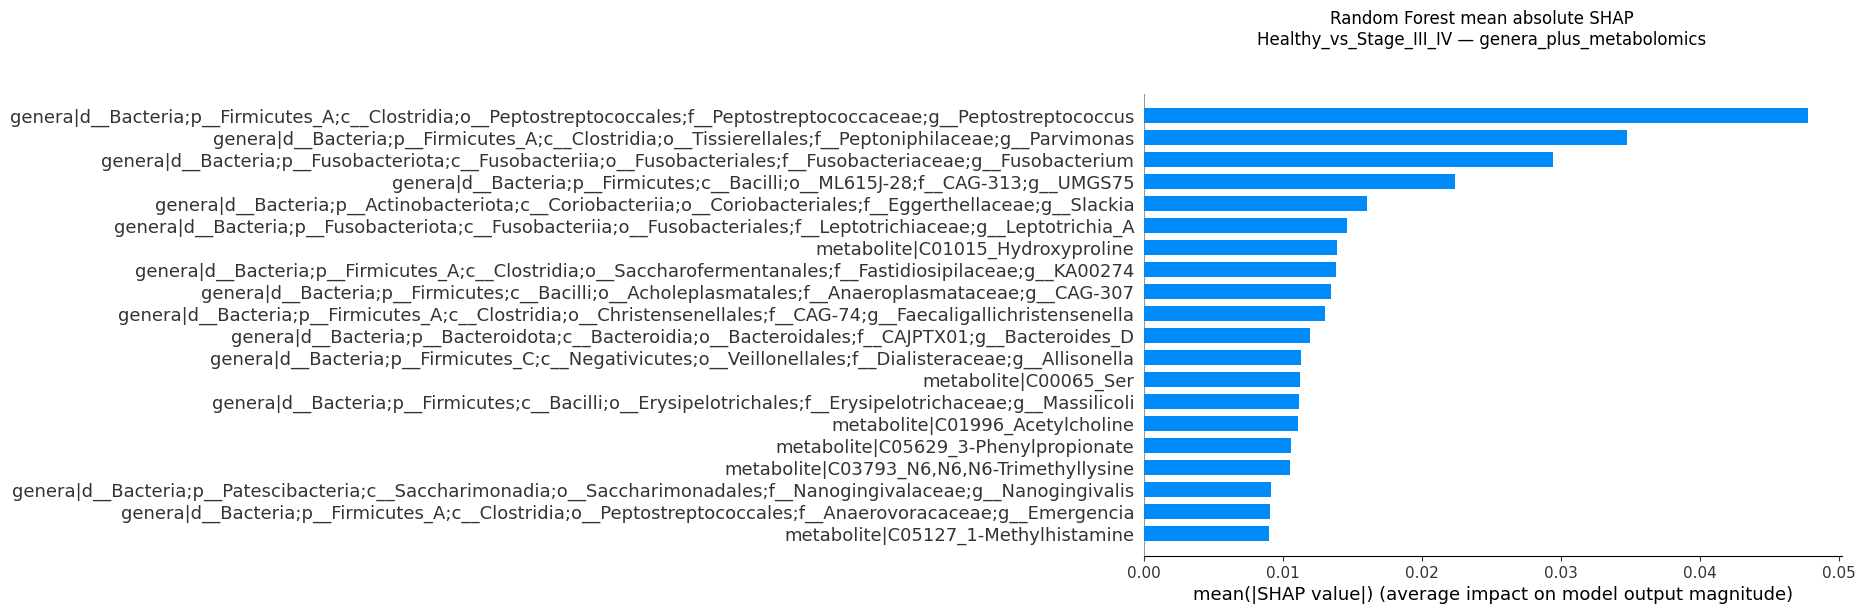

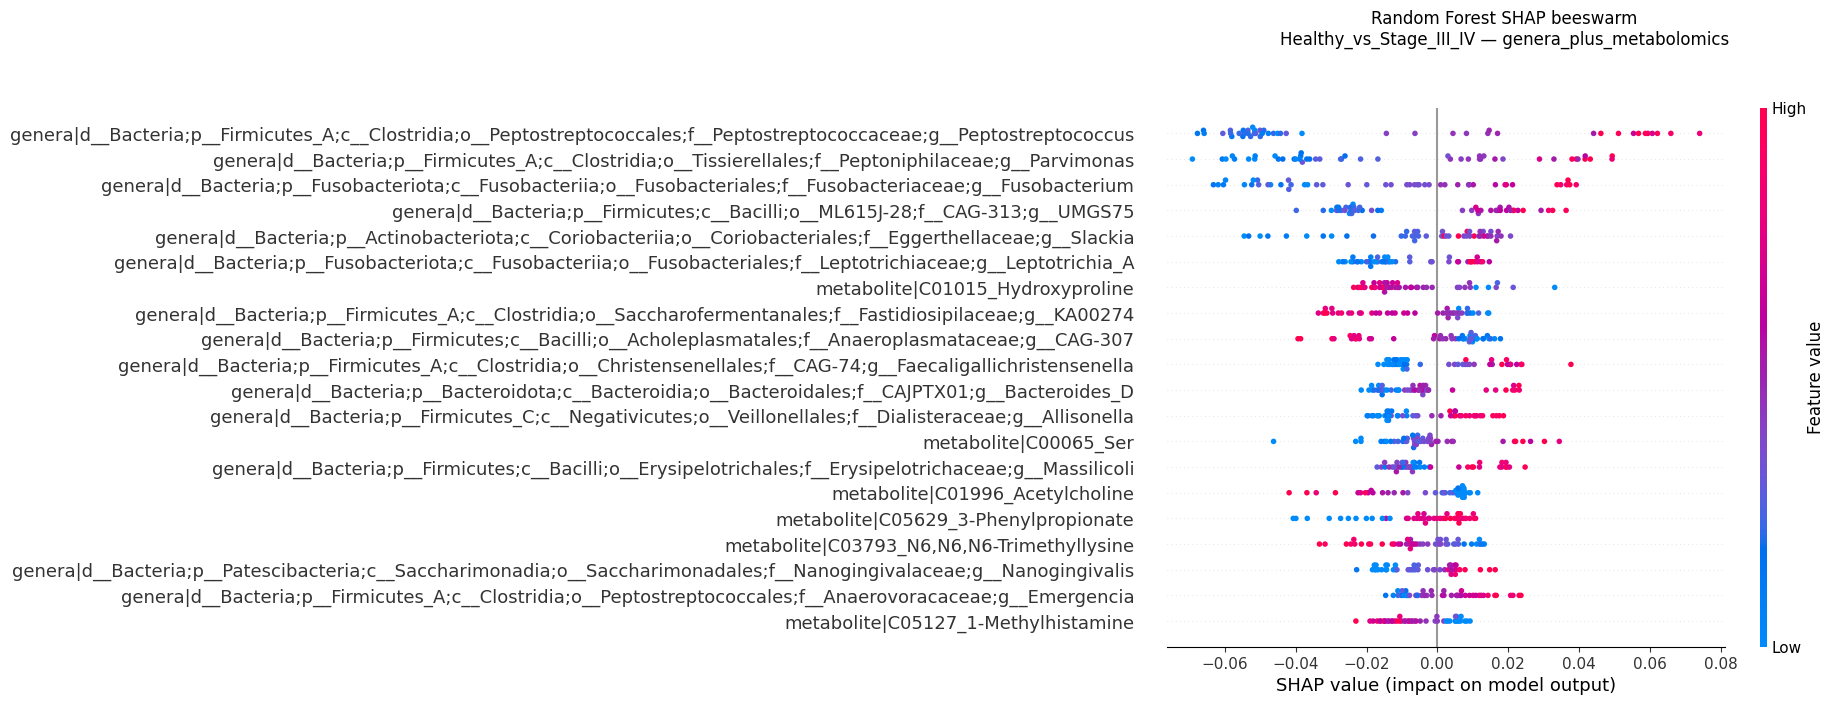

In [17]:
# Random Forest SHAP: rank + bar plot + beeswarm plot


import sys
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score

try:
    from IPython.display import display
except Exception:
    display = print

# SHAP settings


RF_SHAP_CONTRAST = "Healthy_vs_Stage_III_IV"

# RF_SHAP_CONTRAST = "Healthy_vs_Early_CRC"

RF_SHAP_BLOCK = "genera_plus_metabolomics"
RF_SHAP_TOP_N = 20


RF_SHAP_LABELS = {
    "Healthy_vs_Early_CRC": {
        "control": ["Healthy"],
        "disease": ["Stage_0", "Stage_I_II"],
    },
    "Healthy_vs_Stage_III_IV": {
        "control": ["Healthy"],
        "disease": ["Stage_III_IV"],
    },
}



required_names = [
    "metadata",
    "GROUP_COL",
    "ml_blocks",
    "make_rf_pipeline",
    "choose_k",
    "TEST_SIZE",
    "RANDOM_STATE",
    "FAST_MODE",
    "math",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]

if missing_names:
    raise RuntimeError(
        "Please run the notebook from the top through Section 5 first. "
        f"Missing objects: {missing_names}"
    )


if RF_SHAP_CONTRAST not in RF_SHAP_LABELS:
    raise ValueError(
        f"Unsupported contrast: {RF_SHAP_CONTRAST}"
    )


if RF_SHAP_BLOCK not in ml_blocks:
    raise KeyError(
        f"{RF_SHAP_BLOCK!r} is unavailable. "
        f"Available feature blocks: {list(ml_blocks)}"
    )



try:
    import shap

except ImportError:
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "shap",
    ])

    import shap


# Construct the comparison directly from metadata

# Class 0 = Healthy
# Class 1 = CRC group

comparison = RF_SHAP_LABELS[RF_SHAP_CONTRAST]

control_labels = comparison["control"]
disease_labels = comparison["disease"]

X_source = ml_blocks[RF_SHAP_BLOCK]

common_ids = X_source.index.intersection(
    metadata.index
)

groups = metadata.loc[
    common_ids,
    GROUP_COL,
].astype(str)

keep_ids = groups.index[
    groups.isin(
        control_labels + disease_labels
    )
]

X = X_source.loc[
    keep_ids
].copy()

y = (
    groups.loc[keep_ids]
    .isin(disease_labels)
    .astype(int)
)

class_counts = (
    y.value_counts()
    .sort_index()
)


print(f"Contrast: {RF_SHAP_CONTRAST}")
print(f"Feature block: {RF_SHAP_BLOCK}")

print(
    f"Class 0 ({'+'.join(control_labels)}): "
    f"{int(class_counts.get(0, 0))}"
)

print(
    f"Class 1 ({'+'.join(disease_labels)}): "
    f"{int(class_counts.get(1, 0))}"
)


if (
    len(class_counts) != 2
    or int(class_counts.min()) < 4
):
    raise ValueError(
        "Not enough samples for stratified splitting. "
        f"Class counts: {class_counts.to_dict()}"
    )


# Fit Random Forest on a held-out test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)


k = choose_k(
    RF_SHAP_BLOCK,
    X.shape[1],
    X_train.shape[0],
)


rf_pipe = make_rf_pipeline(k)

rf_pipe.fit(
    X_train,
    y_train,
)


test_probability = rf_pipe.predict_proba(
    X_test
)[:, 1]


holdout_auc = roc_auc_score(
    y_test,
    test_probability,
)

holdout_ap = average_precision_score(
    y_test,
    test_probability,
)


print(f"Selected feature count: {k}")
print(f"Holdout ROC AUC: {holdout_auc:.3f}")
print(f"Holdout Average Precision: {holdout_ap:.3f}")


# Apply the fitted preprocessing

imputer = rf_pipe.named_steps[
    "imputer"
]

selector = rf_pipe.named_steps[
    "feature_select"
]


X_test_imputed = imputer.transform(
    X_test
)

X_test_selected = selector.transform(
    X_test_imputed
)


try:
    imputed_names = np.asarray(
        imputer.get_feature_names_out(
            X_train.columns
        ),
        dtype=object,
    )

except Exception:
    imputed_names = np.asarray(
        X_train.columns,
        dtype=object,
    )


support = np.asarray(
    selector.get_support(),
    dtype=bool,
)


if len(imputed_names) != len(support):
    raise ValueError(
        "Feature-name alignment failed: "
        f"{len(imputed_names)} names versus "
        f"{len(support)} selector entries."
    )


selected_names = imputed_names[
    support
]


X_shap = pd.DataFrame(
    X_test_selected,
    index=X_test.index,
    columns=selected_names,
)


print(
    "SHAP test matrix shape:",
    X_shap.shape,
)


# Calculate Random Forest Class-1 SHAP values

rf_model = rf_pipe.named_steps[
    "rf"
]


explainer = shap.TreeExplainer(
    rf_model
)


raw_values = explainer.shap_values(
    X_shap
)


if isinstance(raw_values, list):

    shap_values = np.asarray(
        raw_values[-1]
    )

elif hasattr(raw_values, "values"):

    shap_values = np.asarray(
        raw_values.values
    )

else:

    shap_values = np.asarray(
        raw_values
    )


n_samples, n_features = X_shap.shape


if shap_values.ndim == 3:

    if (
        shap_values.shape[0] == n_samples
        and shap_values.shape[1] == n_features
    ):

        shap_values = shap_values[
            :,
            :,
            -1,
        ]

    elif (
        shap_values.shape[1] == n_samples
        and shap_values.shape[2] == n_features
    ):

        shap_values = shap_values[
            -1,
            :,
            :,
        ]

    else:
        raise ValueError(
            "Unsupported RF SHAP output shape: "
            f"{shap_values.shape}"
        )


if shap_values.ndim != 2:
    raise ValueError(
        "Expected a two-dimensional SHAP matrix, "
        f"received {shap_values.shape}"
    )


if shap_values.shape == (
    n_features,
    n_samples,
):

    shap_values = shap_values.T


if shap_values.shape != (
    n_samples,
    n_features,
):

    raise ValueError(
        f"SHAP shape {shap_values.shape} "
        f"does not match test data shape "
        f"{(n_samples, n_features)}"
    )


print(
    "Final SHAP matrix shape:",
    shap_values.shape,
)



# Rank features using mean absolute SHAP


rf_shap_rank = pd.DataFrame({
    "Feature": X_shap.columns,
    "Mean_Absolute_SHAP": (
        np.abs(shap_values)
        .mean(axis=0)
    ),
})


rf_shap_rank = (
    rf_shap_rank
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False,
    )
    .reset_index(drop=True)
)


rf_shap_rank.insert(
    0,
    "Rank",
    np.arange(
        1,
        len(rf_shap_rank) + 1,
    ),
)


rf_shap_rank["Feature_Type"] = np.select(
    [
        rf_shap_rank[
            "Feature"
        ].str.startswith("genera|"),

        rf_shap_rank[
            "Feature"
        ].str.startswith("metabolite|"),
    ],
    [
        "Genus",
        "Metabolite",
    ],
    default="Other",
)


print("\nTop Random Forest SHAP features:")

display(
    rf_shap_rank.head(
        RF_SHAP_TOP_N
    )
)


# Mean absolute SHAP bar plot


shap.summary_plot(
    shap_values,
    X_shap,
    plot_type="bar",
    max_display=min(
        RF_SHAP_TOP_N,
        n_features,
    ),
    show=False,
)


fig = plt.gcf()

fig.set_size_inches(
    9,
    6,
)

fig.suptitle(
    "Random Forest mean absolute SHAP\n"
    f"{RF_SHAP_CONTRAST} — {RF_SHAP_BLOCK}",
    y=1.02,
)

fig.tight_layout()

plt.show()

plt.close(fig)


# 10. SHAP beeswarm plot


shap.summary_plot(
    shap_values,
    X_shap,
    max_display=min(
        RF_SHAP_TOP_N,
        n_features,
    ),
    show=False,
)


fig = plt.gcf()

fig.set_size_inches(
    9,
    7,
)

fig.suptitle(
    "Random Forest SHAP beeswarm\n"
    f"{RF_SHAP_CONTRAST} — {RF_SHAP_BLOCK}",
    y=1.02,
)

fig.tight_layout()

plt.show()

plt.close(fig)

## 7. Package outputs

In [18]:
# organize output
archive_path = Path(shutil.make_archive(str(OUT_DIR), "zip", root_dir=OUT_DIR))
print(f"Created output archive: {archive_path}")
if IN_COLAB:
    print("Download it from the Colab file browser, or run:")
    print(f"from google.colab import files; files.download(r'{archive_path}')")

Created output archive: /content/02_Yachida_RF_LASSO_results.zip
Download it from the Colab file browser, or run:
from google.colab import files; files.download(r'/content/02_Yachida_RF_LASSO_results.zip')
